# Etapa 1 — Limpieza de Datos
## Predicción del Riesgo de Anemia en Niños de 6 a 35 meses en el Perú
**Fuente:** ENDES 2025 — INEI  
**Modelo objetivo:** XGBoost  
**Definición de anemia:** OMS 2024 / RM 251-2024-MINSA (`HW57A`)

---

## 0. Configuración e Importaciones

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore')

# Estilo visual
sns.set_theme(style='whitegrid', palette='Set2', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 5)

# Rutas
ROOT      = os.path.dirname(os.getcwd())  # proyecto_anemia_xgboost/
RAW       = os.path.join(ROOT, 'data', 'raw')
PROCESSED = os.path.join(ROOT, 'data', 'processed')
REPORTS   = os.path.join(ROOT, 'reports')
os.makedirs(PROCESSED, exist_ok=True)
os.makedirs(REPORTS, exist_ok=True)

def to_num(s):
    """Convierte serie (posiblemente con espacios/blancos) a numérico."""
    return pd.to_numeric(s.astype(str).str.strip(), errors='coerce')

print('Configuración lista. ROOT:', ROOT)

Configuración lista. ROOT: /home/hearelmer/Downloads/anemia2


---
## 1. Carga de Módulos y Exploración Inicial

La ENDES 2025 organiza los datos en módulos separados por temática. Cargamos los 4 módulos relevantes:

| Módulo | Archivo(s) | Contenido |
|--------|-----------|----------|
| 1638 | `REC44` | Hemoglobina, nivel de anemia, peso y talla del niño → **TARGET** |
| 1629 | `RECH0` | Conglomerado, peso muestral, región, altitud |
| 1630 | `RECH23` | Agua, saneamiento, piso, índice de riqueza |
| 1633 | `REC41` | Embarazo, parto, controles prenatales, lactancia |

In [2]:
ARCHIVOS = {
    'REC44':  ('1638 — Anemia (TARGET)',   os.path.join(RAW, 'REC44_2025.csv')),
    'RECH0':  ('1629 — Hogar',             os.path.join(RAW, 'RECH0_2025.csv')),
    'RECH23': ('1630 — Vivienda',          os.path.join(RAW, 'RECH23_2025.csv')),
    'REC41':  ('1633 — Embarazo/Parto',    os.path.join(RAW, 'REC41_2025.csv')),
    'REC94':  ('1633 — Suplemento [DUDOSA]', os.path.join(RAW, 'REC94_2025.csv')),
}

dfs = {}
resumen = []
for nombre, (desc, path) in ARCHIVOS.items():
    df = pd.read_csv(path, low_memory=False, encoding='utf-8-sig')
    df.columns = df.columns.str.strip()
    dfs[nombre] = df
    resumen.append({'Archivo': nombre, 'Descripción': desc,
                    'Filas': df.shape[0], 'Columnas': df.shape[1]})

df_res = pd.DataFrame(resumen)
df_res

,Archivo,Descripción,Filas,Columnas
0,REC44,1638 — Anemia (TARGET),18841,34
1,RECH0,1629 — Hogar,37331,44
2,RECH23,1630 — Vivienda,37331,130
3,REC41,1633 — Embarazo/Parto,18841,147
4,REC94,1633 — Suplemento [DUDOSA],18841,61


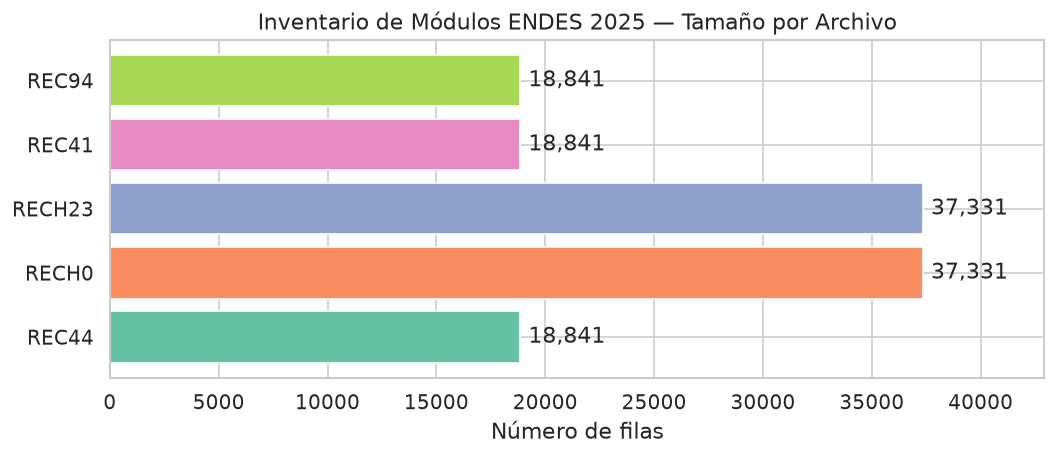

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
colores = sns.color_palette('Set2', len(df_res))
bars = ax.barh(df_res['Archivo'], df_res['Filas'], color=colores)
ax.bar_label(bars, labels=[f"{v:,}" for v in df_res['Filas']], padding=5)
ax.set_xlabel('Número de filas')
ax.set_title('Inventario de Módulos ENDES 2025 — Tamaño por Archivo')
ax.set_xlim(0, df_res['Filas'].max() * 1.15)
plt.tight_layout()
plt.show()

---
## 2. Inspección del Módulo TARGET (REC44)

### 2.1 Variables clave de hemoglobina y anemia

> **Importante:** El módulo ya trae la hemoglobina **ajustada por altitud** (`HW56A`) y el **nivel de anemia** clasificado (`HW57A`) según la nueva directriz OMS 2024 / RM 251-2024-MINSA. No necesitamos recalcular nada.

In [4]:
rec44 = dfs['REC44'].copy()

vars_clave = {
    'HW1':   'Edad en meses',
    'HW55':  'Resultado medición hemo',
    'HW53':  'Hemo cruda x10 [LEAKAGE]',
    'HW56A': 'Hemo ajustada OMS2024 x10 [LEAKAGE]',
    'HW57A': 'Nivel anemia OMS2024 ← TARGET BASE',
    'HW70':  'Z-score Talla/Edad x100',
    'HW71':  'Z-score Peso/Edad x100',
    'HW72':  'Z-score Peso/Talla x100',
    'HW73':  'Z-score IMC x100',
}

tabla = []
for col, desc in vars_clave.items():
    if col in rec44.columns:
        s = to_num(rec44[col])
        tabla.append({'Variable': col, 'Descripción': desc,
                      'No-nulos': s.notna().sum(),
                      'Min': s.min(), 'Max': s.max(),
                      'Media': round(s.mean(), 1)})

pd.DataFrame(tabla).set_index('Variable')

,Descripción,No-nulos,Min,Max,Media
Variable,,,,,
HW1,Edad en meses,18289,0.0,59.0,30.5
HW55,Resultado medición hemo,18841,0.0,9.0,0.8
HW53,Hemo cruda x10 [LEAKAGE],18289,50.0,999.0,196.4
HW56A,Hemo ajustada OMS2024 x10 [LEAKAGE],18289,46.0,999.0,189.5
HW57A,Nivel anemia OMS2024 ← TARGET BASE,18289,1.0,9.0,4.1
HW70,Z-score Talla/Edad x100,18289,-572.0,9999.0,63.9
HW71,Z-score Peso/Edad x100,18289,-503.0,9999.0,139.9
HW72,Z-score Peso/Talla x100,18289,-498.0,9999.0,202.3
HW73,Z-score IMC x100,18289,-493.0,9999.0,209.3


### 2.2 Resultado de la medición de hemoglobina (HW55)

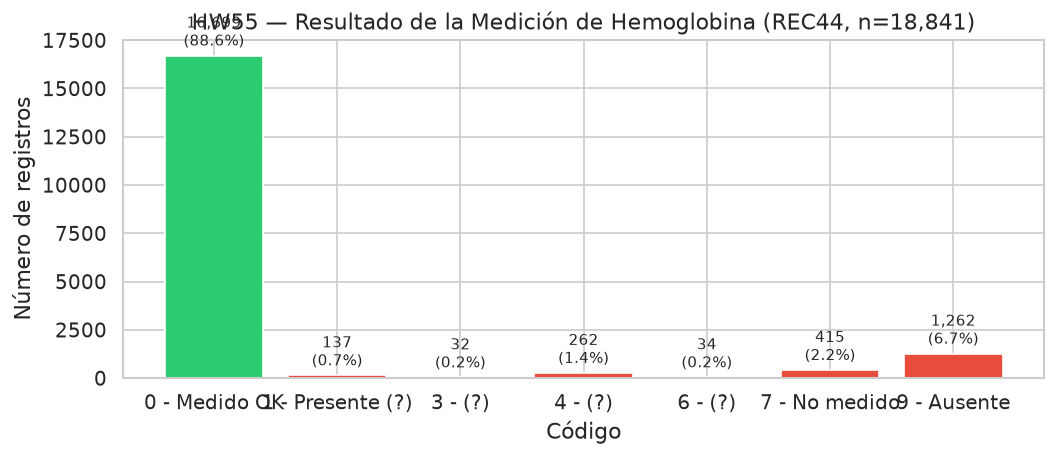

Solo se conservan los registros con HW55=0 (medición exitosa): 16,699 (88.6%)


In [5]:
hw55_labels = {0: '0 - Medido OK', 1: '1 - Presente (?)',
               3: '3 - (?)', 4: '4 - (?)', 6: '6 - (?)',
               7: '7 - No medido', 9: '9 - Ausente'}
hw55_vc = to_num(rec44['HW55']).value_counts().sort_index()
hw55_vc.index = [hw55_labels.get(int(i), str(i)) for i in hw55_vc.index]

fig, ax = plt.subplots(figsize=(9, 4))
colores = ['#2ecc71' if '0' in l else '#e74c3c' for l in hw55_vc.index]
bars = ax.bar(hw55_vc.index, hw55_vc.values, color=colores, edgecolor='white')
ax.bar_label(bars, labels=[f"{v:,}\n({100*v/len(rec44):.1f}%)" for v in hw55_vc.values],
             padding=3, fontsize=9)
ax.set_title('HW55 — Resultado de la Medición de Hemoglobina (REC44, n=18,841)')
ax.set_ylabel('Número de registros')
ax.set_xlabel('Código')
plt.tight_layout()
plt.show()
print('Solo se conservan los registros con HW55=0 (medición exitosa): 16,699 (88.6%)')

### 2.3 Distribución del nivel de anemia (HW57A) — OMS 2024

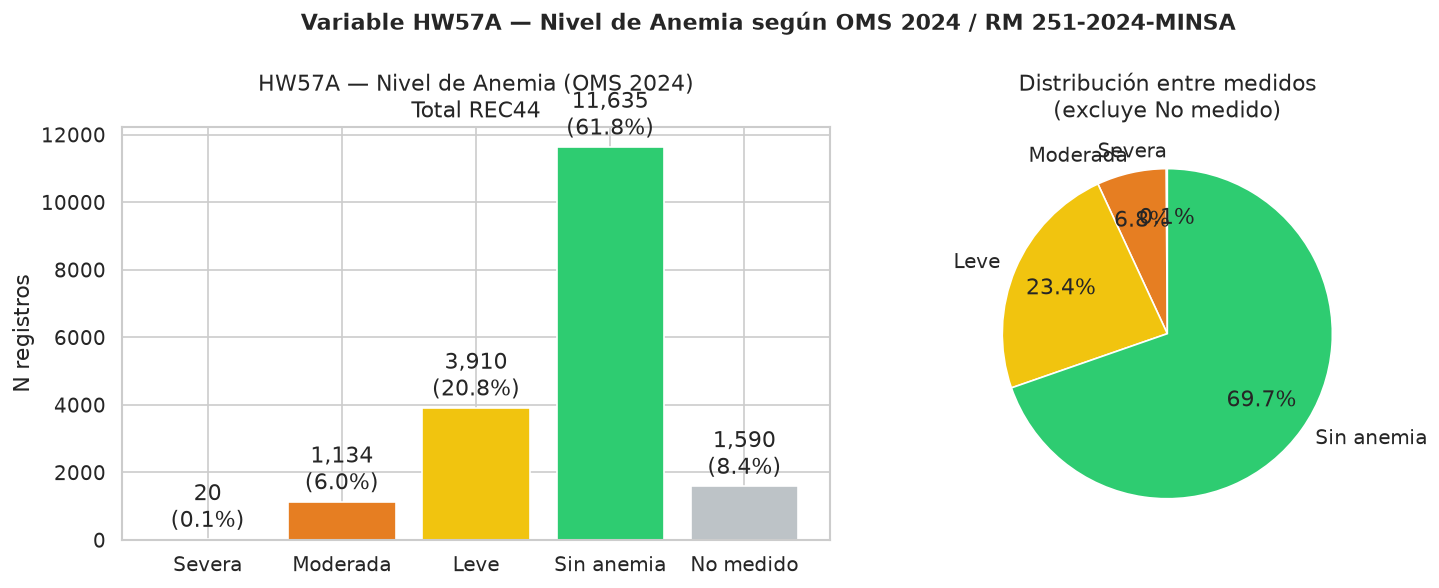

In [6]:
labels_anemia = {1: 'Severa', 2: 'Moderada', 3: 'Leve', 4: 'Sin anemia', 9: 'No medido'}
hw57a_vc = to_num(rec44['HW57A']).value_counts().sort_index()
hw57a_vc.index = [labels_anemia.get(int(i), str(i)) for i in hw57a_vc.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Barras
colores = ['#c0392b', '#e67e22', '#f1c40f', '#2ecc71', '#bdc3c7']
bars = ax1.bar(hw57a_vc.index, hw57a_vc.values, color=colores, edgecolor='white')
ax1.bar_label(bars, labels=[f"{v:,}\n({100*v/len(rec44):.1f}%)" for v in hw57a_vc.values], padding=3)
ax1.set_title('HW57A — Nivel de Anemia (OMS 2024)\nTotal REC44')
ax1.set_ylabel('N registros')

# Pie (solo los que tienen medición, excluyendo 'No medido')
medidos = hw57a_vc.drop('No medido', errors='ignore')
ax2.pie(medidos.values, labels=medidos.index, colors=colores[:4],
        autopct='%1.1f%%', startangle=90, pctdistance=0.7)
ax2.set_title('Distribución entre medidos\n(excluye No medido)')

plt.suptitle('Variable HW57A — Nivel de Anemia según OMS 2024 / RM 251-2024-MINSA', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 3. Filtro del Universo de Estudio

Se conservan únicamente niños de **6 a 35 meses** con **medición de hemoglobina válida** (`HW55 = 0`).

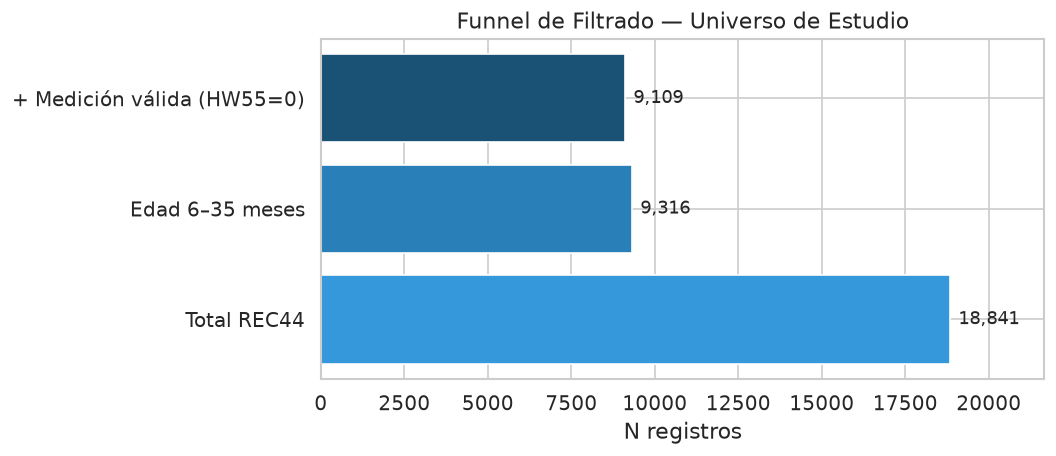

Universo de estudio: 9,109 niños


In [7]:
rec44['HW1_num']  = to_num(rec44['HW1'])
rec44['HW55_num'] = to_num(rec44['HW55'])

mask_edad = rec44['HW1_num'].between(6, 35)
mask_meds = rec44['HW55_num'] == 0

# Diagrama de flujo textual
etapas = [
    ('Total REC44', len(rec44)),
    ('Edad 6–35 meses', mask_edad.sum()),
    ('+ Medición válida (HW55=0)', (mask_edad & mask_meds).sum()),
]

fig, ax = plt.subplots(figsize=(9, 4))
colores_f = ['#3498db', '#2980b9', '#1a5276']
bars = ax.barh([e[0] for e in etapas], [e[1] for e in etapas], color=colores_f)
ax.bar_label(bars, labels=[f"{v:,}" for _, v in etapas], padding=5, fontsize=11)
ax.set_xlabel('N registros')
ax.set_title('Funnel de Filtrado — Universo de Estudio')
ax.set_xlim(0, len(rec44) * 1.15)
plt.tight_layout()
plt.show()

universo = rec44[mask_edad & mask_meds].copy()
print(f'Universo de estudio: {len(universo):,} niños')

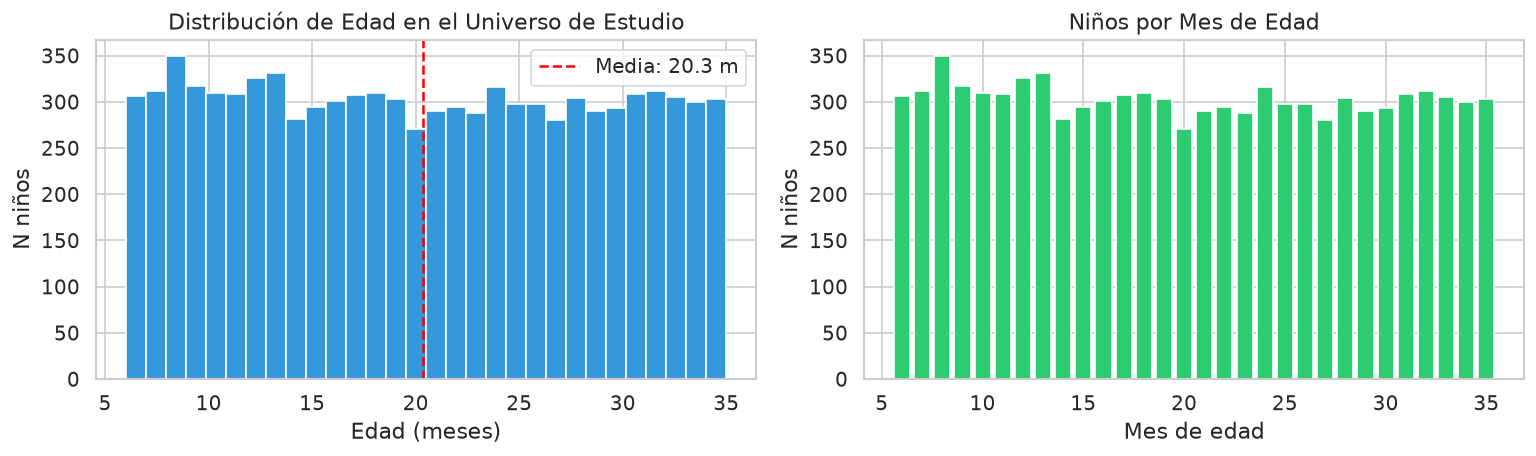

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

# Histograma de edad
ax1.hist(universo['HW1_num'].dropna(), bins=30, color='#3498db', edgecolor='white')
ax1.axvline(universo['HW1_num'].mean(), color='red', linestyle='--', label=f"Media: {universo['HW1_num'].mean():.1f} m")
ax1.set_xlabel('Edad (meses)')
ax1.set_ylabel('N niños')
ax1.set_title('Distribución de Edad en el Universo de Estudio')
ax1.legend()

# Conteo por mes exacto
conteo_mes = universo['HW1_num'].value_counts().sort_index()
ax2.bar(conteo_mes.index, conteo_mes.values, color='#2ecc71', edgecolor='white', width=0.8)
ax2.set_xlabel('Mes de edad')
ax2.set_ylabel('N niños')
ax2.set_title('Niños por Mes de Edad')

plt.tight_layout()
plt.show()

---
## 4. Unión de Módulos (Merge)

Se usa **LEFT JOIN** desde REC44 como tabla base, para no perder niños aunque les falte información en módulos auxiliares.

| Join | Llave |
|------|-------|
| REC44 → REC41 | `CASEID` + `MIDX == HWIDX` |
| base → RECH0 | `HHID` |
| base → RECH23 | `HHID` |

In [9]:
# Construir llaves
universo = universo.copy()
universo['caseid_clean'] = universo['CASEID'].astype(str).str.strip()
universo['hhid_key']     = universo['caseid_clean'].str[:9].str.strip().astype(int)
universo['hwidx_key']    = to_num(universo['HWIDX'])

# REC41
rec41 = dfs['REC41'].copy()
rec41['caseid_clean'] = rec41['CASEID'].astype(str).str.strip()
rec41['midx_num']     = to_num(rec41['MIDX'])
rec41 = rec41.drop(columns=['ID1', 'CASEID', 'MIDX'], errors='ignore')

n0 = len(universo)
universo = universo.merge(rec41, left_on=['caseid_clean','hwidx_key'],
                          right_on=['caseid_clean','midx_num'], how='left')
n1 = len(universo)

# RECH0
rech0 = dfs['RECH0'].copy().drop(columns=['ID1'], errors='ignore')
universo = universo.merge(rech0, left_on='hhid_key', right_on='HHID', how='left')
n2 = len(universo)

# RECH23
rech23 = dfs['RECH23'].copy().drop(columns=['ID1'], errors='ignore')
cols_nuevas = ['HHID'] + [c for c in rech23.columns if c not in universo.columns]
universo = universo.merge(rech23[cols_nuevas], left_on='hhid_key', right_on='HHID', how='left')
n3 = len(universo)

# Verificación
df_join = pd.DataFrame({
    'Paso': ['Base inicial (REC44 filtrado)', '+ REC41 (embarazo)', '+ RECH0 (hogar)', '+ RECH23 (vivienda)'],
    'Filas': [n0, n1, n2, n3],
    'Diff':  [0, n1-n0, n2-n1, n3-n2],
    'Estado': ['OK', '✅ 0 duplicados', '✅ 0 duplicados', '✅ 0 duplicados']
})
print('Verificación de integridad en los joins:')
display(df_join)
print(f'\nShape final base unida: {universo.shape}')

Verificación de integridad en los joins:


,Paso,Filas,Diff,Estado
0,Base inicial (REC44 filtrado),9109,0,OK
1,+ REC41 (embarazo),9109,0,✅ 0 duplicados
2,+ RECH0 (hogar),9109,0,✅ 0 duplicados
3,+ RECH23 (vivienda),9109,0,✅ 0 duplicados



Shape final base unida: (9109, 356)


---
## 5. Variable Objetivo — `anemia`

**Fuente:** `HW57A` (Nivel de Anemia según OMS 2024 / RM 251-2024-MINSA)  
**Codificación:**
- `1, 2, 3` → `anemia = 1` (severa, moderada o leve)
- `4` → `anemia = 0` (sin anemia)
- `9` → `NaN` (no medido — excluir)

In [10]:
hw57a = to_num(universo['HW57A'])
universo['anemia'] = np.where(hw57a.isin([1,2,3]), 1,
                     np.where(hw57a == 4, 0, np.nan))

n_excluidos = universo['anemia'].isna().sum()
universo = universo[universo['anemia'].notna()].copy()
universo['anemia'] = universo['anemia'].astype(int)

print(f'Excluidos por HW57A=9 (no medido): {n_excluidos}')
print(f'Registros finales: {len(universo):,}')

# Eliminar leakage
leakage = ['HW53','HW56','HW56A','HW57','HW57A','HW1_num','HW55_num','midx_num']
universo = universo.drop(columns=[c for c in leakage if c in universo.columns])
print(f'Variables de leakage eliminadas: {[c for c in leakage if c not in universo.columns]}')

Excluidos por HW57A=9 (no medido): 0
Registros finales: 9,109
Variables de leakage eliminadas: ['HW53', 'HW56', 'HW56A', 'HW57', 'HW57A', 'HW1_num', 'HW55_num', 'midx_num']


---
## 6. Selección y Limpieza de Variables Predictoras

In [11]:
VARIABLES = {
    # Diseño muestral
    'CASEID':   ('id_caso',                  'Identificador único'),
    'HWIDX':    ('idx_nino',                 'Índice niño'),
    'hhid_key': ('id_hogar',                 'Identificador hogar'),
    'HV001':    ('conglomerado',             'Conglomerado (diseño muestral)'),
    'HV022':    ('estrato',                  'Estrato (diseño muestral)'),
    'HV005':    ('peso_muestral',            'Factor ponderación HV005/1e6'),
    # Niño
    'HW1':      ('edad_meses',               'Edad en meses'),
    'HW2':      ('peso_g_x10',               'Peso x10'),
    'HW3':      ('talla_mm_x10',             'Talla x10'),
    'HW70':     ('zscore_haz',               'Z-score Talla/Edad x100'),
    'HW71':     ('zscore_waz',               'Z-score Peso/Edad x100'),
    'HW72':     ('zscore_whz',               'Z-score Peso/Talla x100'),
    'HW73':     ('zscore_baz',               'Z-score IMC x100'),
    # Hogar
    'HV024':    ('region',                   'Región (1=Costa,2=Sierra,3=Selva)'),
    'HV025':    ('area',                     'Área (1=Urbana,2=Rural)'),
    'HV040':    ('altitud_m',                'Altitud metros s.n.m.'),
    'HV009':    ('n_miembros',               'N miembros hogar'),
    'HV014':    ('n_menores5',               'N menores 5 años'),
    # Vivienda
    'HV201':    ('fuente_agua',              'Fuente de agua'),
    'HV205':    ('tipo_sanitario',           'Tipo sanitario'),
    'HV206':    ('tiene_elect',              'Tiene electricidad'),
    'HV213':    ('material_piso',            'Material piso'),
    'HV270':    ('indice_riqueza',           'Índice riqueza (quintil 1-5)'),
    'HV271':    ('puntaje_riqueza',          'Puntaje continuo riqueza'),
    # Embarazo
    'M1':       ('lugar_parto',              'Lugar del parto'),
    'M4':       ('lactancia_dura',           'Duración lactancia (meses)'),
    'M5':       ('lactancia_exclusiva',      'Lactancia exclusiva meses'),
    'M14':      ('n_controles_prenatales',   'N controles prenatales'),
    'M17':      ('asistio_parto',            'Asistencia profesional parto'),
    'M18':      ('inicio_prenatal',          'Mes inicio prenatal'),
    'M19':      ('peso_nacer_g',             'Peso al nacer (g)'),
    'M36':      ('meses_prev_nacer',         'Meses desde nac anterior'),
    'M45':      ('actualmente_amamanta',     'Actualmente amamanta'),
}

cols_ok = [c for c in VARIABLES if c in universo.columns]
df = universo[cols_ok + ['anemia']].copy()
df = df.rename(columns={orig: info[0] for orig, info in VARIABLES.items()})

# Peso muestral / 1e6
df['peso_muestral'] = to_num(df['peso_muestral']) / 1_000_000

# Escalar peso y talla
df['peso_kg']  = to_num(df['peso_g_x10']) / 10
df['talla_cm'] = to_num(df['talla_mm_x10']) / 10
df = df.drop(columns=['peso_g_x10','talla_mm_x10'], errors='ignore')

# Z-scores / 100
for col in ['zscore_haz','zscore_waz','zscore_whz','zscore_baz']:
    if col in df.columns:
        df[col] = to_num(df[col]) / 100

# Códigos especiales → NaN
CODIGOS = [9996, 9997, 9998, 9999, 999]
for col in df.select_dtypes(include='number').columns:
    if col in ['anemia','conglomerado','estrato','id_hogar','peso_muestral']:
        continue
    df[col] = df[col].apply(lambda x: np.nan if pd.notna(x) and x in CODIGOS else x)

print(f'Base limpia: {df.shape}')
df.dtypes

Base limpia: (9109, 34)


id_caso                       str
idx_nino                    int64
id_hogar                    int64
conglomerado                int64
estrato                     int64
peso_muestral             float64
edad_meses                    str
zscore_haz                float64
zscore_waz                float64
zscore_whz                float64
zscore_baz                float64
region                      int64
area                        int64
altitud_m                   int64
n_miembros                  int64
n_menores5                  int64
fuente_agua                   str
tipo_sanitario                str
tiene_elect                   str
material_piso                 str
indice_riqueza                str
puntaje_riqueza               str
lugar_parto                   str
lactancia_dura              int64
lactancia_exclusiva         int64
n_controles_prenatales        str
asistio_parto               int64
inicio_prenatal             int64
peso_nacer_g              float64
meses_prev_nac

---
## 7. Análisis de Valores Perdidos (Missing Values)

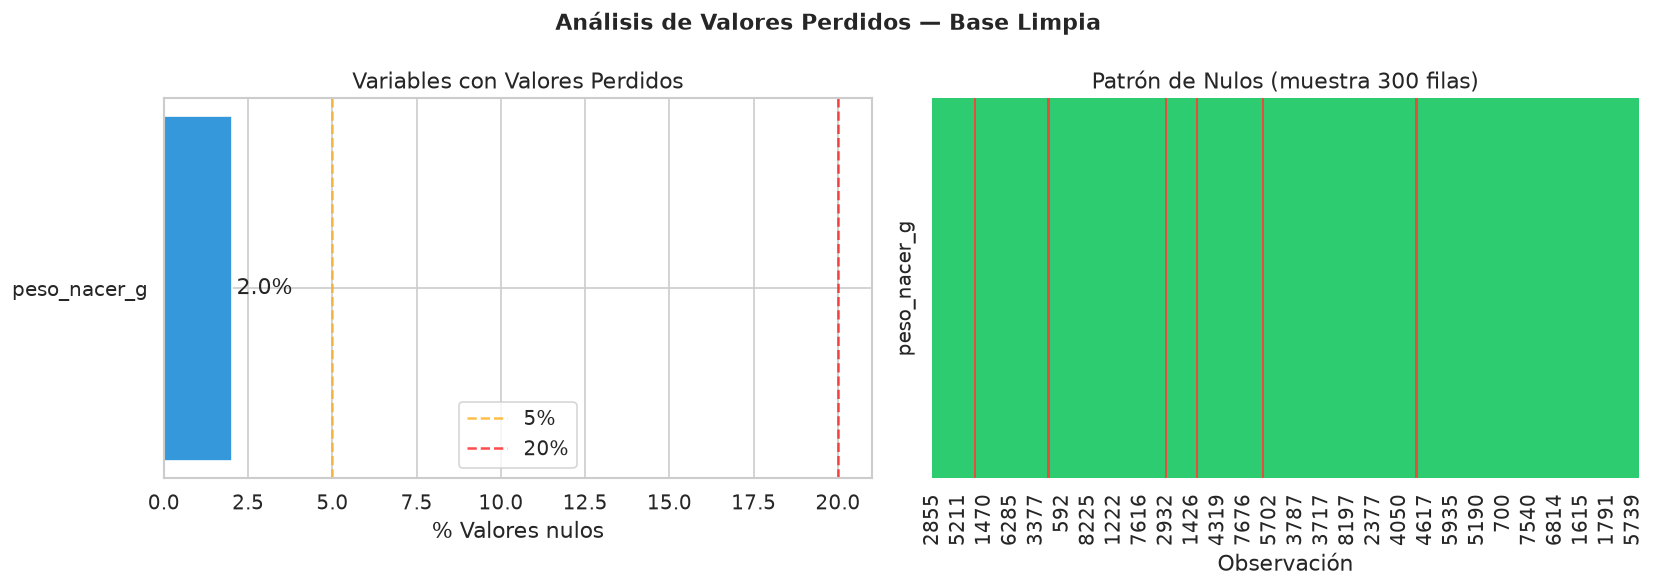


Decisión: XGBoost maneja NaN nativamente → NO se imputa sin justificación.
Máximo % nulo: 2.0 % — umbral aceptable para XGBoost.


In [12]:
nulos = df.isnull().mean().mul(100).sort_values(ascending=False)
nulos_filtro = nulos[nulos > 0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Barras de nulos
colores_n = ['#e74c3c' if v > 20 else '#f39c12' if v > 5 else '#3498db' 
             for v in nulos_filtro.values]
bars = ax1.barh(nulos_filtro.index, nulos_filtro.values, color=colores_n)
ax1.bar_label(bars, labels=[f"{v:.1f}%" for v in nulos_filtro.values], padding=3)
ax1.set_xlabel('% Valores nulos')
ax1.set_title('Variables con Valores Perdidos')
ax1.axvline(5, color='orange', linestyle='--', alpha=0.7, label='5%')
ax1.axvline(20, color='red', linestyle='--', alpha=0.7, label='20%')
ax1.legend()

# Heatmap de nulos (muestra aleatoria de 200 filas)
sample = df[nulos_filtro.index].sample(min(300, len(df)), random_state=42)
sns.heatmap(sample.isnull().T, cbar=False, yticklabels=True,
            cmap=['#2ecc71','#e74c3c'], ax=ax2)
ax2.set_title('Patrón de Nulos (muestra 300 filas)')
ax2.set_xlabel('Observación')

plt.suptitle('Análisis de Valores Perdidos — Base Limpia', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nDecisión: XGBoost maneja NaN nativamente → NO se imputa sin justificación.')
print('Máximo % nulo:', nulos_filtro.max().round(1), '% — umbral aceptable para XGBoost.')

---
## 8. Prevalencia de Anemia — Con y Sin Pesos Muestrales

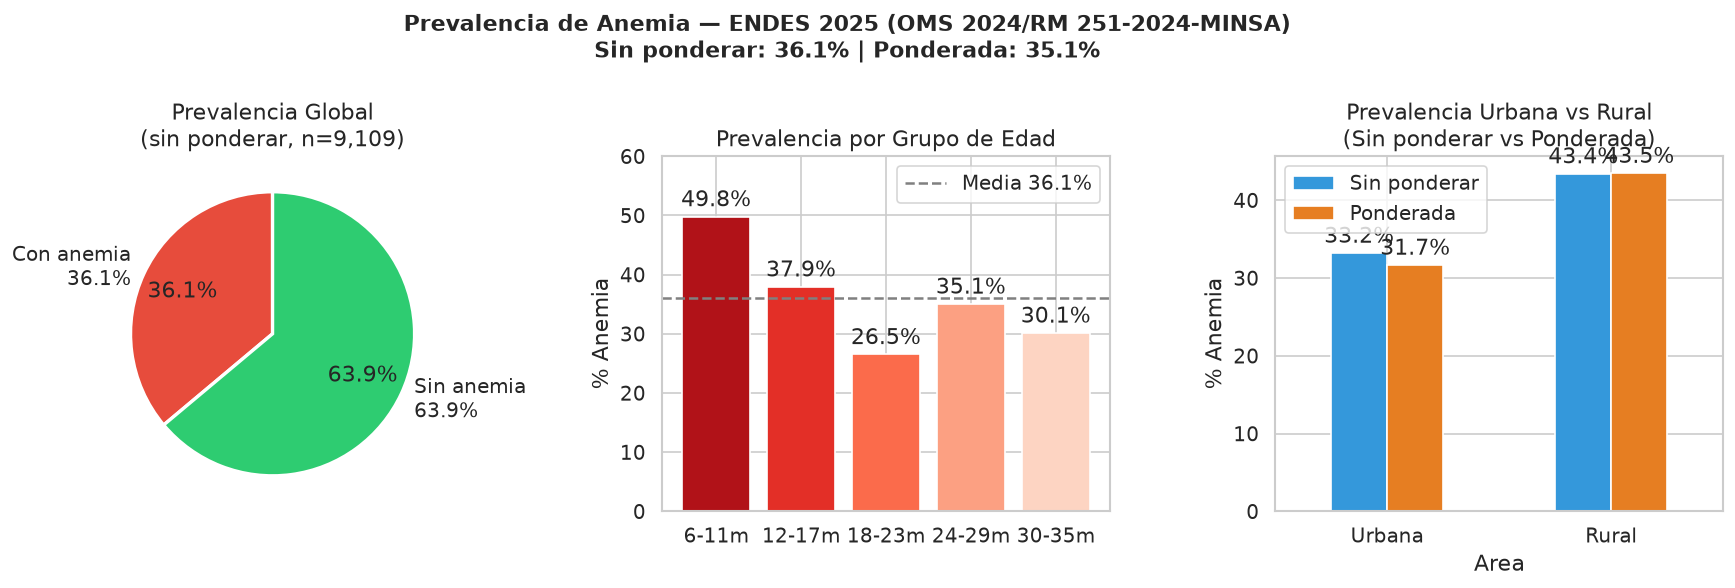

In [13]:
# General
n_total  = len(df)
n_anemia = df['anemia'].sum()
pct_sp   = 100 * n_anemia / n_total

w = df['peso_muestral'].fillna(df['peso_muestral'].median())
pct_cp = 100 * (w * df['anemia']).sum() / w.sum()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# -- Panel 1: General --
ax = axes[0]
vals = [pct_sp, 100-pct_sp]
ax.pie(vals, labels=[f'Con anemia\n{pct_sp:.1f}%', f'Sin anemia\n{100-pct_sp:.1f}%'],
       colors=['#e74c3c','#2ecc71'], autopct='%1.1f%%', startangle=90,
       pctdistance=0.7, wedgeprops=dict(edgecolor='white', linewidth=2))
ax.set_title(f'Prevalencia Global\n(sin ponderar, n={n_total:,})')

# -- Panel 2: Por grupo de edad --
ax = axes[1]
df['grupo_edad'] = pd.cut(to_num(df['edad_meses']),
                          bins=[5,11,17,23,29,35],
                          labels=['6-11m','12-17m','18-23m','24-29m','30-35m'])
tab_edad = df.groupby('grupo_edad', observed=True)['anemia'].agg(
    n='count', n_anemia='sum'
).assign(prev=lambda x: 100*x.n_anemia/x.n)

bars = ax.bar(tab_edad.index.astype(str), tab_edad['prev'],
              color=sns.color_palette('Reds_r', len(tab_edad)), edgecolor='white')
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in tab_edad['prev']], padding=3)
ax.set_ylim(0, 60)
ax.axhline(pct_sp, color='gray', linestyle='--', label=f'Media {pct_sp:.1f}%')
ax.set_title('Prevalencia por Grupo de Edad')
ax.set_ylabel('% Anemia')
ax.legend()

# -- Panel 3: Por área (urbana/rural) y comparación sin/con pesos --
ax = axes[2]
labels_area = {1: 'Urbana', 2: 'Rural'}
df['area_n'] = to_num(df['area'])

areas = []
for cod, nombre in labels_area.items():
    sub = df[df['area_n'] == cod]
    n = len(sub)
    prev_sp = 100 * sub['anemia'].sum() / n
    w2 = sub['peso_muestral'].fillna(sub['peso_muestral'].median())
    prev_cp = 100 * (w2 * sub['anemia']).sum() / w2.sum()
    areas.append({'Area': nombre, 'Sin ponderar': prev_sp, 'Ponderada': prev_cp})

df_areas = pd.DataFrame(areas).set_index('Area')
df_areas.plot(kind='bar', ax=ax, color=['#3498db','#e67e22'], edgecolor='white', rot=0)
ax.set_title('Prevalencia Urbana vs Rural\n(Sin ponderar vs Ponderada)')
ax.set_ylabel('% Anemia')
ax.legend()
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.1f%%', padding=3)

plt.suptitle(f'Prevalencia de Anemia — ENDES 2025 (OMS 2024/RM 251-2024-MINSA)\n'
             f'Sin ponderar: {pct_sp:.1f}% | Ponderada: {pct_cp:.1f}%',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

df = df.drop(columns=['grupo_edad','area_n'], errors='ignore')

---
## 9. Análisis Exploratorio de Variables Numéricas

### 9.1 Boxplots: Variables continuas por clase de anemia

> Un boxplot por variable nos muestra si hay diferencias visuales entre niños con y sin anemia. Esto anticipa qué variables podrían ser importantes para XGBoost.

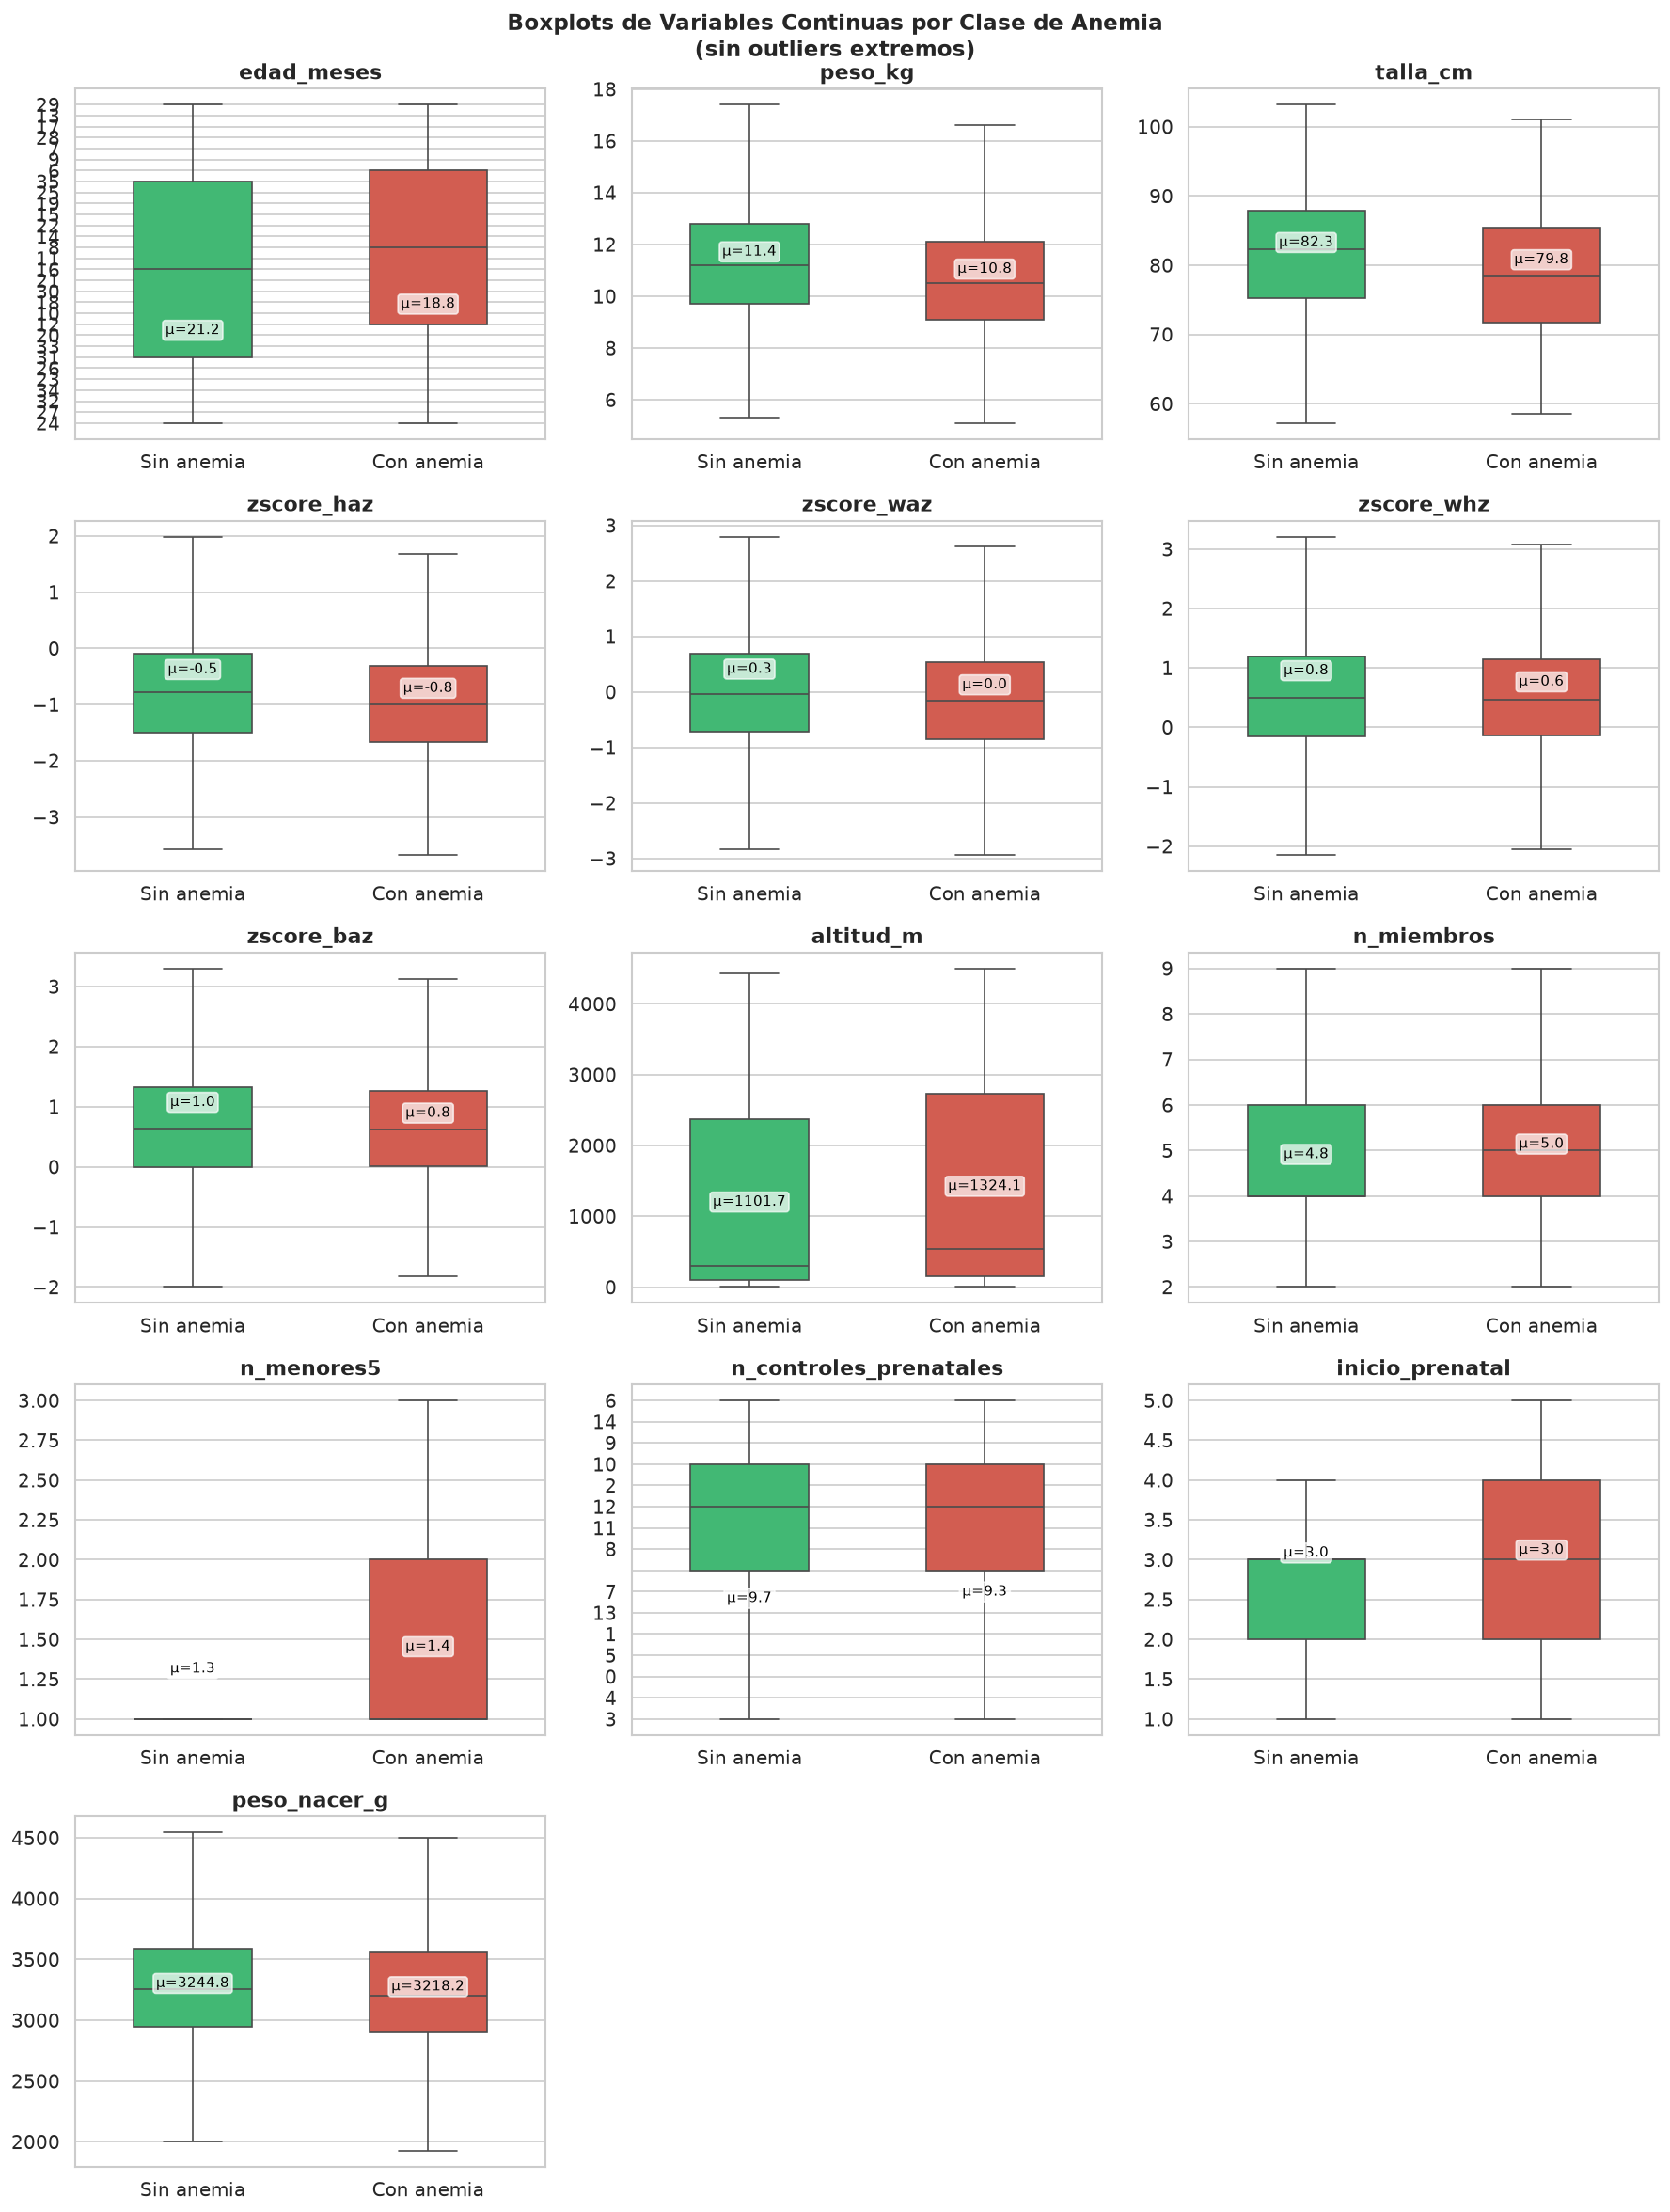

In [14]:
vars_num = ['edad_meses','peso_kg','talla_cm',
            'zscore_haz','zscore_waz','zscore_whz','zscore_baz',
            'altitud_m','n_miembros','n_menores5',
            'n_controles_prenatales','inicio_prenatal','peso_nacer_g']

vars_num = [v for v in vars_num if v in df.columns]
labels_clase = {0: 'Sin anemia', 1: 'Con anemia'}
df['anemia_label'] = df['anemia'].map(labels_clase)

n_cols = 3
n_rows = (len(vars_num) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

paleta = {'Sin anemia': '#2ecc71', 'Con anemia': '#e74c3c'}

for i, var in enumerate(vars_num):
    ax = axes[i]
    data_plot = df[[var, 'anemia_label']].dropna()
    if data_plot.empty:
        ax.set_visible(False)
        continue
    sns.boxplot(data=data_plot, x='anemia_label', y=var,
                palette=paleta, ax=ax, width=0.5,
                showfliers=False)   # sin outliers para mayor claridad
    ax.set_title(var, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    # Medias
    for j, clase in enumerate(['Sin anemia','Con anemia']):
        m = pd.to_numeric(data_plot[data_plot['anemia_label']==clase][var], errors='coerce').mean()
        ax.annotate(f'μ={m:.1f}', xy=(j, m), ha='center', va='bottom',
                    fontsize=9, color='black',
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7))

# Ocultar ejes sobrantes
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplots de Variables Continuas por Clase de Anemia\n(sin outliers extremos)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
df = df.drop(columns=['anemia_label'], errors='ignore')

### 9.2 Violinplots: Z-scores antropométricos por anemia

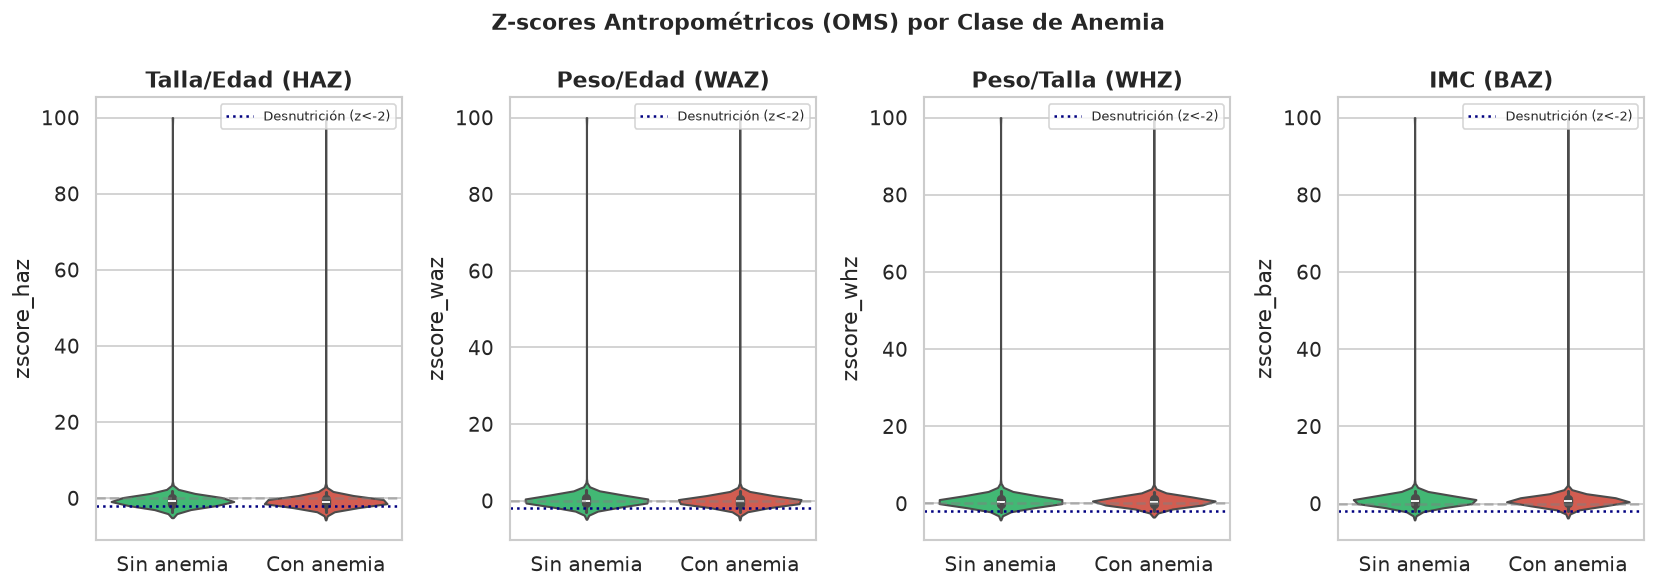

In [15]:
zscores = [c for c in ['zscore_haz','zscore_waz','zscore_whz','zscore_baz'] if c in df.columns]
df['anemia_label'] = df['anemia'].map({0: 'Sin anemia', 1: 'Con anemia'})

fig, axes = plt.subplots(1, len(zscores), figsize=(14, 5))
if len(zscores) == 1: axes = [axes]
nombres = {'zscore_haz': 'Talla/Edad (HAZ)',
           'zscore_waz': 'Peso/Edad (WAZ)',
           'zscore_whz': 'Peso/Talla (WHZ)',
           'zscore_baz': 'IMC (BAZ)'}

for ax, var in zip(axes, zscores):
    data_v = df[[var,'anemia_label']].dropna()
    sns.violinplot(data=data_v, x='anemia_label', y=var,
                   palette={'Sin anemia':'#2ecc71','Con anemia':'#e74c3c'},
                   ax=ax, inner='box', cut=0)
    ax.axhline(-2, color='navy', linestyle=':', label='Desnutrición (z<-2)')
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_title(nombres.get(var, var), fontweight='bold')
    ax.set_xlabel('')
    ax.legend(fontsize=8)

plt.suptitle('Z-scores Antropométricos (OMS) por Clase de Anemia', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
df = df.drop(columns=['anemia_label'], errors='ignore')

### 9.3 Prevalencia por variables categóricas clave

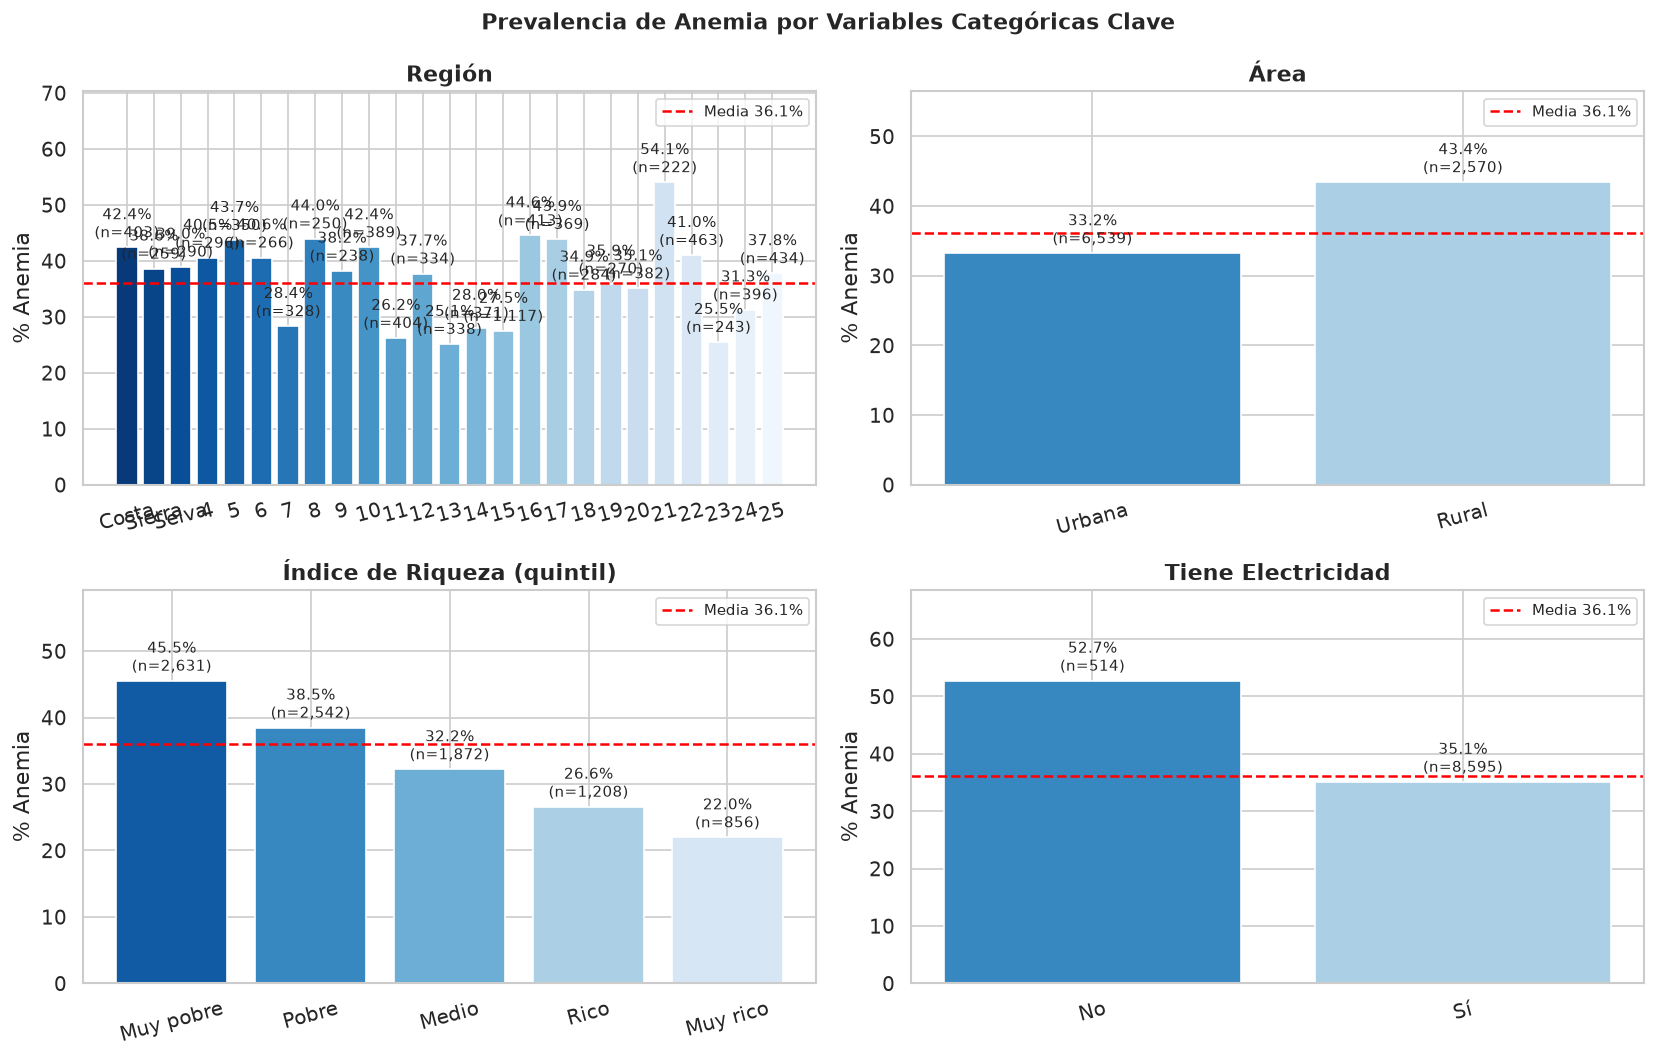

In [16]:
# Región, área, índice de riqueza, electricidad
categoricas = [
    ('region', 'Región', {1:'Costa', 2:'Sierra', 3:'Selva'}),
    ('area', 'Área', {1:'Urbana', 2:'Rural'}),
    ('indice_riqueza', 'Índice de Riqueza (quintil)', {1:'Muy pobre',2:'Pobre',3:'Medio',4:'Rico',5:'Muy rico'}),
    ('tiene_elect', 'Tiene Electricidad', {0:'No',1:'Sí'}),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, (col, titulo, labels) in zip(axes, categoricas):
    if col not in df.columns:
        ax.set_visible(False)
        continue
    tmp = df[[col,'anemia']].copy()
    tmp[col] = to_num(tmp[col])
    tab = tmp.groupby(col, observed=True)['anemia'].agg(
        n='count', n_an='sum'
    ).assign(prev=lambda x: 100*x.n_an/x.n)
    tab.index = [labels.get(int(i), str(i)) for i in tab.index]

    bars = ax.bar(tab.index.astype(str), tab['prev'],
                  color=sns.color_palette('Blues_r', len(tab)), edgecolor='white')
    ax.bar_label(bars, labels=[f"{v:.1f}%\n(n={int(n):,})" 
                                for v,n in zip(tab['prev'],tab['n'])], padding=3, fontsize=9)
    ax.axhline(pct_sp, color='red', linestyle='--', label=f'Media {pct_sp:.1f}%')
    ax.set_title(titulo, fontweight='bold')
    ax.set_ylabel('% Anemia')
    ax.set_ylim(0, tab['prev'].max() * 1.3)
    ax.legend(fontsize=9)
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=15)

plt.suptitle('Prevalencia de Anemia por Variables Categóricas Clave', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 9.4 Altitud y Prevalencia de Anemia

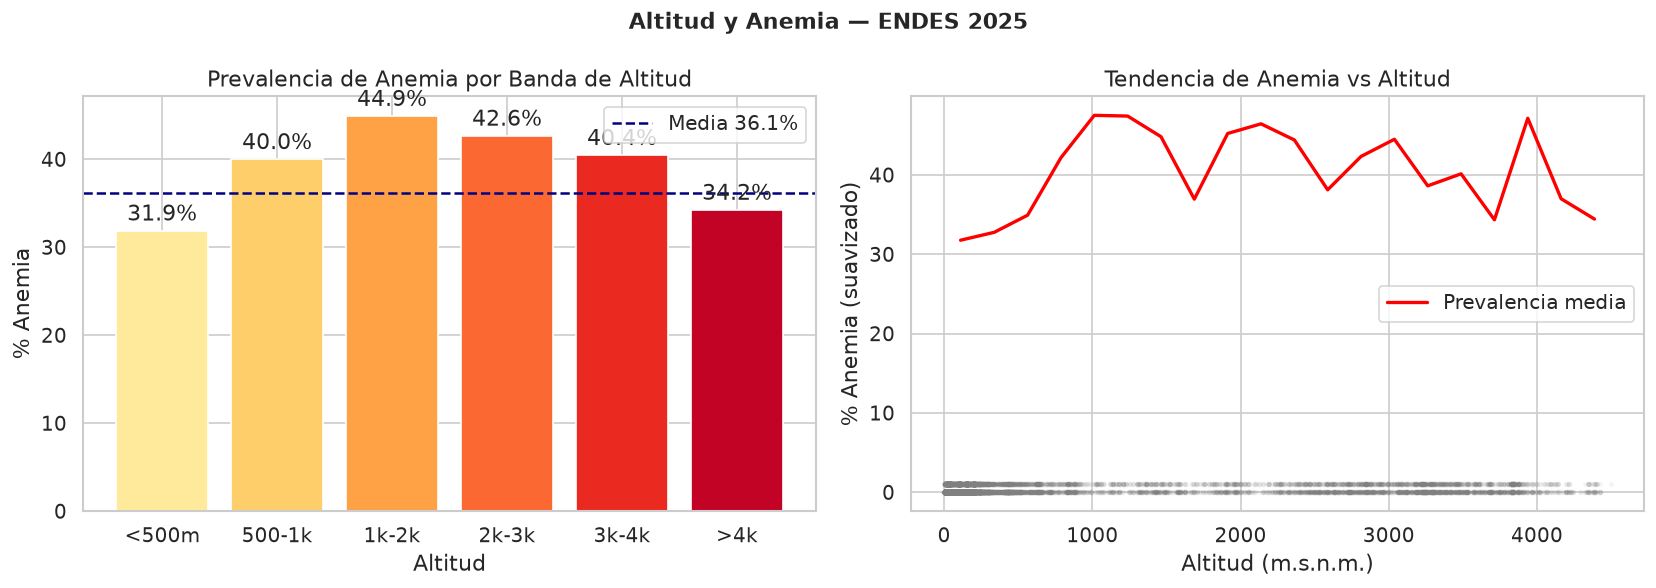

In [17]:
if 'altitud_m' in df.columns:
    df['banda_altitud'] = pd.cut(to_num(df['altitud_m']),
                                  bins=[0,500,1000,2000,3000,4000,6000],
                                  labels=['<500m','500-1k','1k-2k','2k-3k','3k-4k','>4k'])
    tab_alt = df.groupby('banda_altitud', observed=True)['anemia'].agg(
        n='count', n_an='sum'
    ).assign(prev=lambda x: 100*x.n_an/x.n)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Prevalencia por banda
    bars = ax1.bar(tab_alt.index.astype(str), tab_alt['prev'],
                   color=sns.color_palette('YlOrRd', len(tab_alt)), edgecolor='white')
    ax1.bar_label(bars, labels=[f"{v:.1f}%" for v in tab_alt['prev']], padding=3)
    ax1.axhline(pct_sp, color='navy', linestyle='--', label=f'Media {pct_sp:.1f}%')
    ax1.set_title('Prevalencia de Anemia por Banda de Altitud')
    ax1.set_ylabel('% Anemia')
    ax1.set_xlabel('Altitud')
    ax1.legend()

    # Scatterplot altitud vs anemia
    alt_data = df[['altitud_m','anemia']].dropna()
    alt_data['altitud_m'] = to_num(alt_data['altitud_m'])
    # Media deslizante
    alt_sorted = alt_data.sort_values('altitud_m')
    ax2.scatter(alt_sorted['altitud_m'], alt_sorted['anemia'],
                alpha=0.05, color='gray', s=5)
    # Suavizado
    alt_sorted['bin'] = pd.cut(alt_sorted['altitud_m'], bins=20)
    smooth = alt_sorted.groupby('bin', observed=True)['anemia'].mean() * 100
    midpoints = [(b.left + b.right)/2 for b in smooth.index]
    ax2.plot(midpoints, smooth.values, color='red', linewidth=2, label='Prevalencia media')
    ax2.set_xlabel('Altitud (m.s.n.m.)')
    ax2.set_ylabel('% Anemia (suavizado)')
    ax2.set_title('Tendencia de Anemia vs Altitud')
    ax2.legend()

    plt.suptitle('Altitud y Anemia — ENDES 2025', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

    df = df.drop(columns=['banda_altitud'], errors='ignore')

### 9.5 Matriz de Correlación — Variables Numéricas

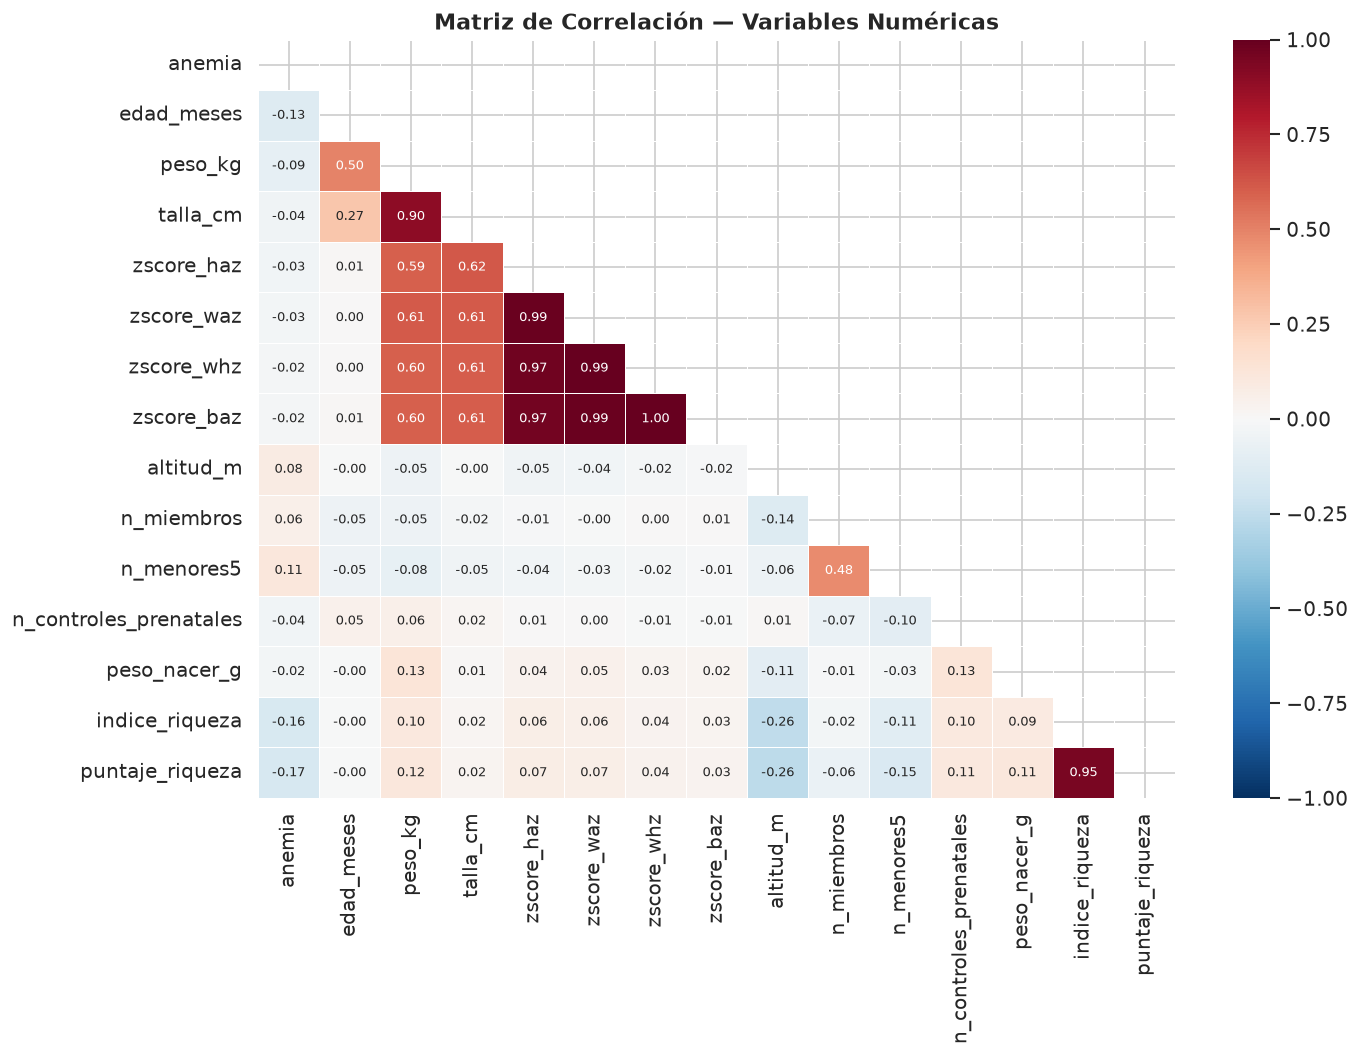

Correlación con el target (anemia):
puntaje_riqueza          -0.169
indice_riqueza           -0.162
edad_meses               -0.131
n_menores5                0.114
peso_kg                  -0.088
altitud_m                 0.078
n_miembros                0.060
talla_cm                 -0.040
n_controles_prenatales   -0.037
zscore_haz               -0.032
zscore_waz               -0.027
peso_nacer_g             -0.024
zscore_whz               -0.018
zscore_baz               -0.017


In [18]:
vars_corr = ['anemia','edad_meses','peso_kg','talla_cm',
             'zscore_haz','zscore_waz','zscore_whz','zscore_baz',
             'altitud_m','n_miembros','n_menores5',
             'n_controles_prenatales','peso_nacer_g',
             'indice_riqueza','puntaje_riqueza']
vars_corr = [v for v in vars_corr if v in df.columns]

df_corr = df[vars_corr].copy()
for col in df_corr.columns:
    df_corr[col] = to_num(df_corr[col])

corr = df_corr.corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax,
            linewidths=0.5, annot_kws={'size': 8})
ax.set_title('Matriz de Correlación — Variables Numéricas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Correlaciones con el target
print('Correlación con el target (anemia):')
print(corr['anemia'].drop('anemia').sort_values(key=abs, ascending=False).round(3).to_string())

---
## 10. Guardar Base Limpia y Diccionario de Variables

In [19]:
# Guardar base limpia
out_parquet = os.path.join(PROCESSED, '03_base_limpia.parquet')
out_csv     = os.path.join(PROCESSED, '03_base_limpia.csv')
df.to_parquet(out_parquet, index=False)
df.to_csv(out_csv, index=False, encoding='utf-8-sig')

print(f'Base limpia guardada:')
print(f'  Parquet : {out_parquet}')
print(f'  CSV     : {out_csv}')
print(f'  Shape   : {df.shape}')
print(f'\nPrevisualización:')
df.head()

Base limpia guardada:
  Parquet : /home/hearelmer/Downloads/anemia2/proyecto_anemia_xgboost/data/processed/03_base_limpia.parquet
  CSV     : /home/hearelmer/Downloads/anemia2/proyecto_anemia_xgboost/data/processed/03_base_limpia.csv
  Shape   : (9109, 34)

Previsualización:


,id_caso,idx_nino,id_hogar,conglomerado,estrato,peso_muestral,edad_meses,zscore_haz,zscore_waz,zscore_whz,...,lactancia_exclusiva,n_controles_prenatales,asistio_parto,inicio_prenatal,peso_nacer_g,meses_prev_nacer,actualmente_amamanta,anemia,peso_kg,talla_cm
0,434400501 2,1,434400501,4344,4,0.073726,29,-0.35,0.25,0.52,...,18,6,0,3,3300.0,,1,0,13.1,89.4
1,434401201 1,1,434401201,4344,4,0.073726,13,-0.40,1.29,1.86,...,13,14,1,2,3140.0,3,1,0,11.4,76.1
2,434407401 2,1,434407401,4344,4,0.073726,13,-1.99,-1.08,-0.17,...,13,9,1,4,3050.0,5,1,0,8.1,70.3
3,434407901 2,1,434407901,4344,4,0.073726,17,-0.36,0.48,0.91,...,16,10,0,3,3395.0,,1,1,11.5,81.1
4,434501401 1,1,434501401,4345,7,0.093465,28,-0.60,-0.44,-0.24,...,12,2,0,3,NaN,,1,0,11.7,87.2


In [20]:
# Diccionario de variables
dict_rows = []
for orig, (nuevo, desc) in VARIABLES.items():
    if nuevo in df.columns:
        pct_nulo = df[nuevo].isnull().mean() * 100
        dict_rows.append({
            'variable_original': orig,
            'variable_limpia':   nuevo,
            'descripcion':       desc,
            'dtype':             str(df[nuevo].dtype),
            'pct_nulo':          round(pct_nulo, 2),
            'decision':          'target' if nuevo=='anemia' else 'diseño muestral' if nuevo in ['conglomerado','estrato','peso_muestral','id_caso','idx_nino','id_hogar'] else 'predictor'
        })

# Agregar target y vars derivadas
dict_rows.append({'variable_original':'HW57A','variable_limpia':'anemia',
                  'descripcion':'TARGET: 1=anemia, 0=sin anemia. Def OMS2024/RM251-2024',
                  'dtype':'int','pct_nulo':0,'decision':'target'})
dict_rows.append({'variable_original':'HW2/10','variable_limpia':'peso_kg',
                  'descripcion':'Peso niño en kg','dtype':'float64',
                  'pct_nulo':round(df['peso_kg'].isnull().mean()*100,2) if 'peso_kg' in df.columns else 0,'decision':'predictor'})
dict_rows.append({'variable_original':'HW3/10','variable_limpia':'talla_cm',
                  'descripcion':'Talla niño en cm','dtype':'float64',
                  'pct_nulo':round(df['talla_cm'].isnull().mean()*100,2) if 'talla_cm' in df.columns else 0,'decision':'predictor'})

df_dict = pd.DataFrame(dict_rows).drop_duplicates('variable_limpia')
df_dict.to_csv(os.path.join(REPORTS,'03_diccionario_variables.csv'), index=False, encoding='utf-8-sig')
print('Diccionario de variables:')
df_dict

Diccionario de variables:


,variable_original,variable_limpia,descripcion,dtype,pct_nulo,decision
0,CASEID,id_caso,Identificador único,str,0.00,diseño muestral
1,HWIDX,idx_nino,Índice niño,int64,0.00,diseño muestral
2,hhid_key,id_hogar,Identificador hogar,int64,0.00,diseño muestral
3,HV001,conglomerado,Conglomerado (diseño muestral),int64,0.00,diseño muestral
4,HV022,estrato,Estrato (diseño muestral),int64,0.00,diseño muestral
5,HV005,peso_muestral,Factor ponderación HV005/1e6,float64,0.00,diseño muestral
6,HW1,edad_meses,Edad en meses,str,0.00,predictor
7,HW70,zscore_haz,Z-score Talla/Edad x100,float64,0.00,predictor
8,HW71,zscore_waz,Z-score Peso/Edad x100,float64,0.00,predictor
9,HW72,zscore_whz,Z-score Peso/Talla x100,float64,0.00,predictor


---
## Resumen Final — Etapa 1

| Métrica | Valor |
|---------|-------|
| Registros originales (REC44) | 18 841 |
| Fuera de rango 6–35 meses | −9 525 |
| Medición no válida (HW55≠0) | −207 |
| **Universo de estudio** | **9 109** |
| Variables leakage eliminadas | 5 |
| **Predictores en base limpia** | **~30** |
| Máx. % nulos | 3.9% |
| Prevalencia sin ponderar | 36.1% |
| Prevalencia ponderada | 35.1% |

**Archivos generados:**
- `data/processed/03_base_limpia.parquet` ← usar en Etapa 2 (EDA) y siguientes
- `data/processed/03_base_limpia.csv`
- `reports/03_diccionario_variables.csv`

**Próxima etapa:** Exploración de Datos (EDA) con visualizaciones más detalladas y análisis bivariado para selección de variables.